# Sorting methods

MCDA methods usually rank the alternatives: the result tells which alternative is better than another one. In many
problems, however, the decision-maker needs to know whether an alternative is *good enough*, e.g. whether a
supplier is acceptable, a loan applicant is low, medium or high risk, or a country is free or repressed. Such
problems are solved by **sorting** methods, which assign every alternative to one of predefined, ordered
categories.

The categories are defined by **profiles**: reference alternatives describing either the limits between the
categories (limiting, boundary profiles) or typical alternatives of each category (central, characteristic
profiles). In sorting methods an alternative is compared with the profiles, not with the other alternatives, so its
category does not change when alternatives are added to or removed from the decision matrix.

The `pymcdm.methods.sorting` module provides three sorting methods:

- `ELECTRE_TRI`, based on the outranking relation of ELECTRE,
- `TOPSIS_SORT`, based on the closeness coefficient of TOPSIS,
- `FLOWSORT`, based on the flows of PROMETHEE.

In `pymcdm` all of them follow the same conventions:

- categories are numbered from 1 (the worst) to $K$ (the best),
- profiles are given in rows of a matrix, ordered from the worst to the best one,
- calling the method returns the number of the category of each alternative, and `verbose=True` gives all the
  intermediate results,
- `rank()` is not available, because categories are not a ranking.

The examples use the numerical examples of the papers which introduced the methods (the same examples are used in
the tests of the library). Papers often number the categories from the best one; the conversion is given in each
example. Two plots from `pymcdm.visuals` help to present the results: `sorting_assignments` and `flowsort_flows`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymcdm.methods.sorting import ELECTRE_TRI, TOPSIS_SORT, FLOWSORT
from pymcdm.visuals import sorting_assignments, flowsort_flows

## ELECTRE TRI

ELECTRE TRI compares each alternative with the limiting profiles using the outranking relation of ELECTRE, built
from concordance and discordance indices with indifference (`q`), preference (`p`) and veto (`v`) thresholds. An
alternative outranks a profile if the credibility of the outranking is at least the cutting level $\lambda$
(`cutting_level`). Two assignment procedures are available:

- **pessimistic** (default): the alternative is assigned to the best category whose lower profile it outranks,
- **optimistic**: the alternative is assigned to the worst category whose upper profile is preferred to it.

The optimistic category is never worse than the pessimistic one; a difference between them shows that the
alternative is incomparable with some profiles.

The example is the banking application of Mousseau et al. (2000): fifteen firms evaluated on seven cost criteria
(lower values are better) are sorted into three categories. The two profiles and the thresholds, which are
different for each profile, are those of Table 1 of the paper, and the cutting level is 0.86.

In [2]:
weights = np.array([3, 1, 1, 1, 1, 1, 2]) / 10
types = -np.ones(7)

# Limits between categories, from the worst to the best (cost criteria: the best profile has the lowest values)
profiles = np.array([[17, 43, 43, 43, 43, 43, 40],
                     [14, 29, 29, 29, 29, 29, 27]])

# Indifference and preference thresholds: one row for each profile
q = np.array([[0.67, 1.84, 1.84, 1.84, 1.84, 1.84, 2.56],
              [0.64, 1.56, 1.56, 1.56, 1.56, 1.56, 2.04]])
p = np.array([[1.34, 3.73, 3.73, 3.73, 3.73, 3.73, 5.19],
              [1.28, 3.17, 3.17, 3.17, 3.17, 3.17, 4.15]])

# Firms a19, a23, a41, a49, a68, a5, a27, a29, a55, a62, a66, a69, a84, a93 and a94 (Table 2)
firms = ['a19', 'a23', 'a41', 'a49', 'a68', 'a5', 'a27', 'a29', 'a55', 'a62', 'a66', 'a69', 'a84', 'a93', 'a94']
matrix = np.array([
    [13.02, 15.74, 18.02, 7.24, 79.21, 42.63, 79.32],
    [13.66, 11.01, 14.11, 70.55, 69.01, 18.77, 42.39],
    [13.04, 7.99, 22.44, 7.24, 31.40, 14.83, 58.65],
    [13.48, 1.05, 18.02, 6.45, 31.40, 18.77, 100.00],
    [9.91, 7.99, 14.11, 7.24, 12.92, 3.02, 58.65],
    [14.43, 11.01, 18.02, 29.25, 22.16, 31.73, 39.44],
    [13.51, 14.02, 18.02, 29.25, 22.16, 8.91, 39.44],
    [13.39, 11.01, 18.02, 17.36, 22.16, 8.91, 39.44],
    [12.14, 7.99, 18.02, 5.46, 22.16, 3.02, 39.44],
    [11.07, 7.99, 18.02, 5.46, 12.92, 3.02, 39.44],
    [10.25, 7.99, 14.11, 15.58, 12.92, 8.91, 20.24],
    [10.65, 11.01, 10.47, 3.69, 3.76, 8.91, 20.24],
    [8.26, 7.99, 10.47, 3.69, 3.76, 3.02, 20.24],
    [3.68, 1.96, 6.74, 15.58, 3.76, 3.02, 20.24],
    [3.86, 1.96, 3.02, 3.69, 3.76, 3.02, 20.24],
])

pessimistic = ELECTRE_TRI(profiles, q=q, p=p, cutting_level=0.86)
optimistic = ELECTRE_TRI(profiles, q=q, p=p, cutting_level=0.86, procedure='optimistic')

electre = pd.DataFrame({
    'Pessimistic': pessimistic(matrix, weights, types),
    'Optimistic': optimistic(matrix, weights, types),
}, index=firms)
electre.T

,a19,a23,a41,a49,a68,a5,a27,a29,a55,a62,a66,a69,a84,a93,a94
Pessimistic,1,1,1,1,1,2,2,2,2,2,3,3,3,3,3
Optimistic,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3


The pessimistic assignments agree with the categories given in the paper. With the high cutting level the profiles
rarely outrank the firms, so the optimistic procedure assigns all of them to the best category, and the paper uses
the pessimistic one. `sorting_assignments` shows the
category of every alternative and, optionally, an interval of categories; here the interval spans the pessimistic
and the optimistic assignment.

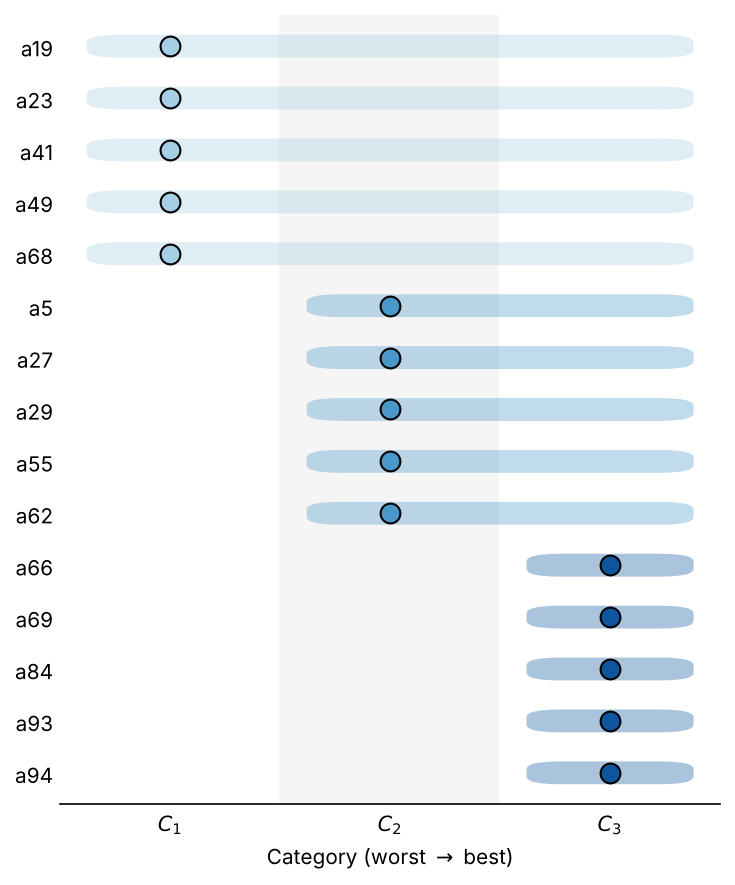

In [3]:
fig, ax = plt.subplots(figsize=(5, 6), dpi=150)
sorting_assignments(electre['Pessimistic'], 3,
                    intervals=electre[['Pessimistic', 'Optimistic']].to_numpy(),
                    labels=firms, ax=ax)
plt.tight_layout()
plt.show()

With `verbose=True` the method returns the concordance indices and the credibility of the outranking in both
directions, which explain the assignments. For example, for the first three firms:

In [4]:
results = pessimistic(matrix[:3], weights, types, verbose=True)
print(results.results[2])
print(results.results[3])

Credibility of the outranking of profiles by alternatives ($\sigma(a, b_h)$)
$A_{i}$  $b_{1}$  $b_{2}$
$A_{1}$   0.7000   0.6000
$A_{2}$   0.8000   0.6000
$A_{3}$   0.8000   0.7478
Credibility of the outranking of alternatives by profiles ($\sigma(b_h, a)$)
$A_{i}$  $b_{1}$  $b_{2}$
$A_{1}$   0.4000   0.5406
$A_{2}$   0.4000   0.7000
$A_{3}$   0.2000   0.4500


## TOPSIS-Sort

TOPSIS-Sort computes the closeness coefficients of the alternatives and of the profiles, as in TOPSIS, with the
ideal and anti-ideal solutions given by the domain of the criteria (`bounds`), as in R-TOPSIS. Since the ideal
solutions do not depend on the alternatives, neither do the closeness coefficients, and an alternative can be
compared with the profiles directly. Two variants are available:

- **TOPSIS-Sort-B** (`profiles_type='boundary'`, default): the alternative is assigned to the category between the
  two boundary profiles which surround its closeness coefficient,
- **TOPSIS-Sort-C** (`profiles_type='characteristic'`): the profiles are typical alternatives of the categories,
  and the category of the closest characteristic profile is chosen.

The example is the evaluation of the economic freedom of ten countries from de Lima Silva & de Almeida Filho
(2020): twelve equally weighted benefit criteria with the domain [0, 100] and five categories, from Repressed (the
worst) to Free (the best). The paper numbers the categories from $C_1$ (Free) to $C_5$ (Repressed), so the
category $c$ of the paper is $6 - c$ here.

In [5]:
freedom = np.array([
    [19.6, 29.6, 25.2, 91.7, 80.3, 99.3, 49.2, 60.4, 76.7, 66.0, 10, 10],
    [54.8, 30.6, 40.4, 86.3, 73.9, 80.6, 69.3, 52.7, 81.5, 87.8, 70, 70],
    [31.6, 36.2, 28.9, 76.4, 48.7, 18.7, 61.6, 49.9, 74.9, 67.4, 30, 30],
    [35.9, 26.6, 20.5, 83.9, 80.7, 58.2, 55.7, 58.8, 55.4, 61.2, 30, 40],
    [47.8, 44.5, 33.5, 69.3, 49.5, 33.0, 56.4, 46.9, 60.2, 70.0, 55, 60],
    [57.2, 46.3, 38.6, 84.7, 79.0, 53.0, 78.3, 71.4, 77.8, 80.8, 75, 70],
    [79.1, 86.5, 79.9, 62.8, 60.1, 86.2, 88.3, 84.1, 86.6, 87.6, 80, 90],
    [84.2, 71.3, 77.4, 50.5, 24.5, 85.5, 74.9, 68.7, 81.5, 86.0, 90, 70],
    [59.1, 53.1, 44.7, 87.5, 59.5, 89.4, 69.5, 63.9, 63.0, 74.6, 60, 60],
    [42.2, 46.9, 43.7, 97.3, 86.8, 65.7, 68.5, 67.5, 78.1, 47.8, 50, 60],
])
freedom_weights = np.ones(12) / 12
freedom_types = np.ones(12)
bounds = np.array([[0, 100]] * 12)

# Scenario 1: boundary profiles with all values equal to 50, 60, 70 and 80
boundary = np.repeat([[50], [60], [70], [80]], 12, axis=1)
# Scenario 2: characteristic profiles, the medians of the intervals
characteristic = np.repeat([[25], [55], [65], [75], [90]], 12, axis=1)

topsis_b = TOPSIS_SORT(boundary, bounds)
topsis_c = TOPSIS_SORT(characteristic, bounds, profiles_type='characteristic')

results_b = topsis_b(freedom, freedom_weights, freedom_types, verbose=True)
print(results_b)

Results for the TOPSIS_SORT method.

Decision matrix ($x_{ij}$)
 $A_{i}$  $C_{1}$  $C_{2}$  $C_{3}$  $C_{4}$  $C_{5}$  $C_{6}$  $C_{7}$  $C_{8}$  $C_{9}$  $C_{10}$  $C_{11}$  $C_{12}$
 $A_{1}$  19.6000  29.6000  25.2000  91.7000  80.3000  99.3000  49.2000  60.4000  76.7000   66.0000        10        10
 $A_{2}$  54.8000  30.6000  40.4000  86.3000  73.9000  80.6000  69.3000  52.7000  81.5000   87.8000        70        70
 $A_{3}$  31.6000  36.2000  28.9000  76.4000  48.7000  18.7000  61.6000  49.9000  74.9000   67.4000        30        30
 $A_{4}$  35.9000  26.6000  20.5000  83.9000  80.7000  58.2000  55.7000  58.8000  55.4000   61.2000        30        40
 $A_{5}$  47.8000  44.5000  33.5000  69.3000  49.5000  33.0000  56.4000  46.9000  60.2000   70.0000        55        60
 $A_{6}$  57.2000  46.3000  38.6000  84.7000  79.0000  53.0000  78.3000  71.4000  77.8000   80.8000        75        70
 $A_{7}$  79.1000  86.5000  79.9000  62.8000  60.1000  86.2000  88.3000  84.1000  86.6000   87.6

In [6]:
countries = [f'A{i + 1}' for i in range(10)]
topsis = pd.DataFrame({
    'Closeness': results_b.results[0].data,
    'TOPSIS-Sort-B': topsis_b(freedom, freedom_weights, freedom_types),
    'TOPSIS-Sort-C': topsis_c(freedom, freedom_weights, freedom_types),
}, index=countries)
topsis.round(4).astype(object).T

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10
Closeness,0.5109,0.6453,0.4667,0.505,0.5207,0.6615,0.7932,0.6918,0.6437,0.6145
TOPSIS-Sort-B,2,3,1,2,2,3,4,3,3,3
TOPSIS-Sort-C,2,3,2,2,2,3,4,3,3,3


Both variants agree with Table 8 of the paper, except $A_3$: its closeness coefficient (0.4667) is below the
boundary 0.5, so TOPSIS-Sort-B assigns it to the worst category, while it is closer to the characteristic profile of
the second category (0.55) than to the one of the worst category (0.25).

## FlowSort

FlowSort computes the PROMETHEE flows of each alternative together with the profiles, i.e. in the set
$R \cup \{a_i\}$, and assigns the alternative to the category whose profiles have similar flows. The categories can
be defined by $K + 1$ limiting profiles $r_1, \ldots, r_{K+1}$ (category $C_h$ lies between $r_h$ and $r_{h+1}$) or by
$K$ central profiles (`profiles_type='central'`). The positive, the negative and the net flow give three
assignments; the returned one is chosen with `rule` ('net' by default) and all of them are available with
`verbose=True`.

The example is the illustrative example of Nemery & Lamboray (2008): three actions evaluated on five equally
weighted criteria and four categories defined by limiting profiles with the values 0, 25, 50, 75 and 100, with the
usual preference function. The paper numbers the categories from 1 (the best), so its category $C_h$ is
$C_{5-h}$ here.

In [7]:
actions = np.array([[54, 17, 71, 45, 63],
                    [15, 5, 19, 9, 23],
                    [25, 25, 50, 75, 75]])
actions_weights = np.ones(5) / 5
actions_types = np.ones(5)

limiting = np.array([[0] * 5, [25] * 5, [50] * 5, [75] * 5, [100] * 5])
flowsort = FLOWSORT(limiting)
results = flowsort(actions, actions_weights, actions_types, verbose=True)
print(results)

Results for the FLOWSORT method.

Decision matrix ($x_{ij}$)
$A_{i}$  $C_{1}$  $C_{2}$  $C_{3}$  $C_{4}$  $C_{5}$
$A_{1}$       54       17       71       45       63
$A_{2}$       15        5       19        9       23
$A_{3}$       25       25       50       75       75

Positive flows of the profiles ($\phi^+(r_h)$)
$A_{i}$  $r_{1}$  $r_{2}$  $r_{3}$  $r_{4}$  $r_{5}$
$A_{1}$   0.0000   0.2400   0.4800   0.8000   1.0000
$A_{2}$   0.0000   0.4000   0.6000   0.8000   1.0000
$A_{3}$   0.0000   0.2000   0.4800   0.7200   1.0000

Negative flows of the profiles ($\phi^-(r_h)$)
$A_{i}$  $r_{1}$  $r_{2}$  $r_{3}$  $r_{4}$  $r_{5}$
$A_{1}$   1.0000   0.7600   0.5200   0.2000   0.0000
$A_{2}$   1.0000   0.6000   0.4000   0.2000   0.0000
$A_{3}$   1.0000   0.7200   0.4800   0.2000   0.0000

Net flows of the profiles ($\phi(r_h)$)
$A_{i}$  $r_{1}$  $r_{2}$  $r_{3}$  $r_{4}$  $r_{5}$
$A_{1}$  -1.0000  -0.5200  -0.0400   0.6000   1.0000
$A_{2}$  -1.0000  -0.2000   0.2000   0.6000   1.0000
$A_{3}$

The flows of the profiles are computed separately for each action, so they are different in every row.
`flowsort_flows` shows them on three axes, one for each flow, together with the flows of the action. All the
axes are oriented so that better categories are on the right, i.e. the axis of the negative flow is reversed.

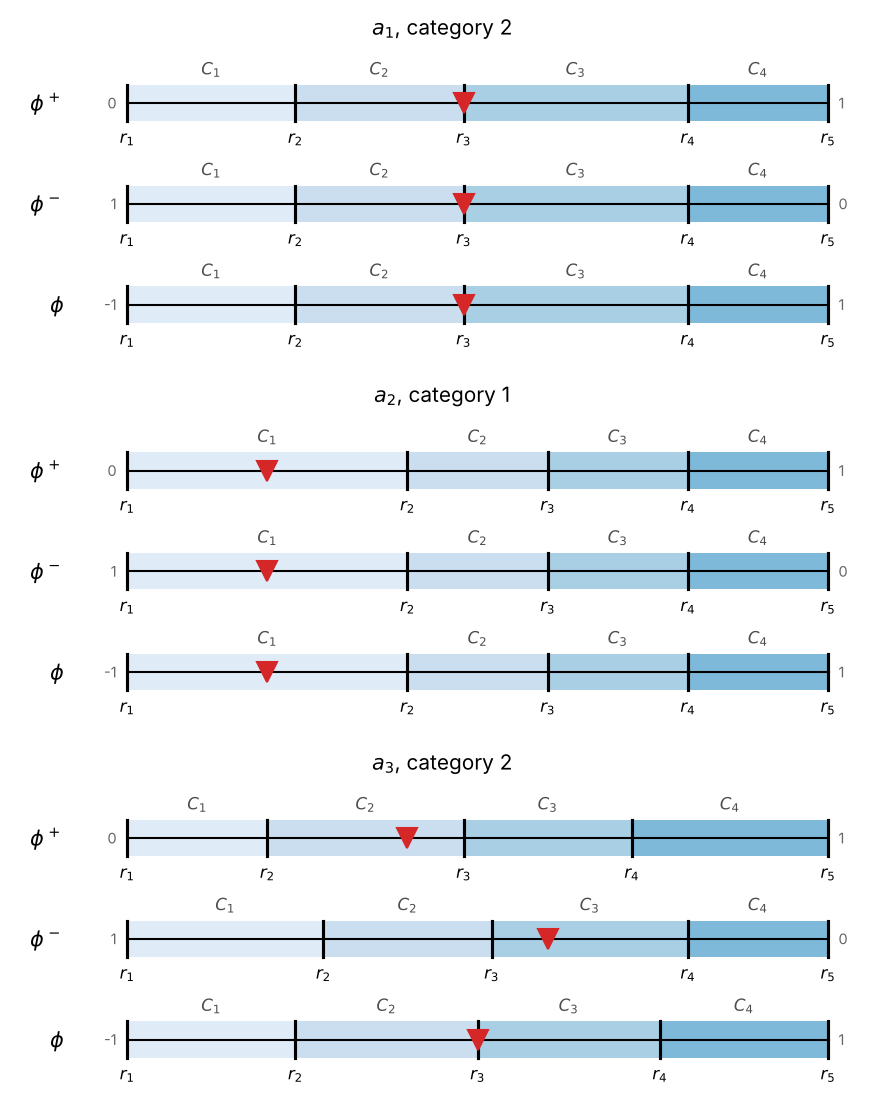

In [8]:
phi_plus_r, phi_minus_r, phi_r, phi_a, categories_all, categories = [r.data for r in results.results]

fig, axes = plt.subplots(3, 1, figsize=(6, 7.5), dpi=150)
for i, ax in enumerate(axes):
    flowsort_flows(phi_plus_r[i], phi_minus_r[i], phi_r[i], phi_a[i], ax=ax)
    ax.set_title(f'$a_{{{i + 1}}}$, category {categories[i]}', fontsize=10)
plt.tight_layout()
plt.show()

$a_1$ and $a_3$ obtain category 2 from the positive and the net flow and category 3 from the negative flow; the
interval of categories can be presented with `sorting_assignments`.

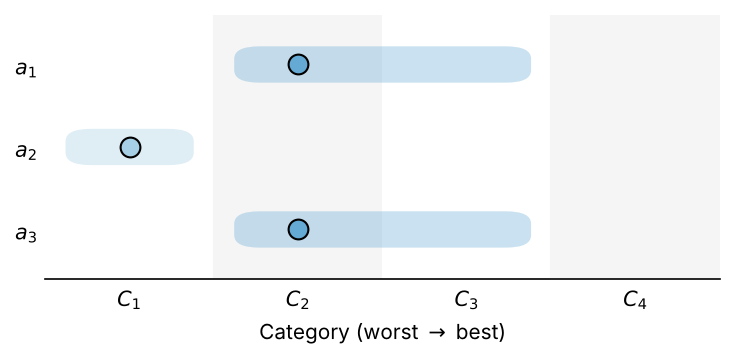

In [9]:
intervals = np.column_stack([categories_all[:, :2].min(axis=1), categories_all[:, :2].max(axis=1)])

fig, ax = plt.subplots(figsize=(5, 2.5), dpi=150)
sorting_assignments(categories, 4, intervals=intervals, labels=['$a_1$', '$a_2$', '$a_3$'], ax=ax)
plt.tight_layout()
plt.show()

With central profiles the categories are described by their typical actions. The second example of the paper uses
four centroids, the V-shape preference function with indifference threshold (`'vshape_2'`) and the thresholds of
Table 8. All three rules assign $a_1$ and $a_3$ to $C_3$ and $a_2$ to $C_1$ ($C_2$ and $C_4$ in the paper).

Categories from the positive, negative and net flows
$A_{i}$  $C_{\phi^+}(a_i)$  $C_{\phi^-}(a_i)$  $C_{\phi}(a_i)$
$A_{1}$                  3                  3                3
$A_{2}$                  1                  1                1
$A_{3}$                  3                  3                3


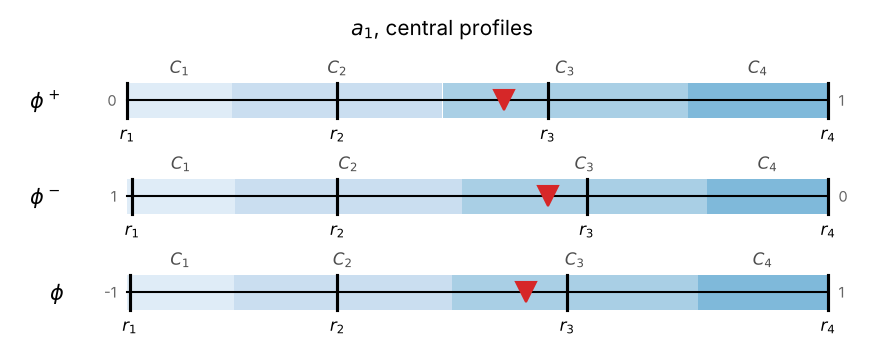

In [10]:
central = np.array([[10, 5, 10, 10, 15],
                    [40, 35, 35, 30, 33],
                    [56, 62, 58, 61, 52],
                    [80, 90, 90, 75, 82]])
flowsort_c = FLOWSORT(central, 'vshape_2', q=[4, 6, 0, 2, 3], p=[8, 13, 7, 5, 12], profiles_type='central')
results_c = flowsort_c(actions, actions_weights, actions_types, verbose=True)
print(results_c.results[-2])

phi_plus_r, phi_minus_r, phi_r, phi_a = [r.data for r in results_c.results[:4]]
fig, ax = plt.subplots(figsize=(6, 2.5), dpi=150)
flowsort_flows(phi_plus_r[0], phi_minus_r[0], phi_r[0], phi_a[0], profiles_type='central', ax=ax)
ax.set_title('$a_1$, central profiles', fontsize=10)
plt.tight_layout()
plt.show()

## Comparison of the methods

The three methods can be applied to the same problem. Below, the economic freedom data are sorted with ELECTRE TRI
and FlowSort using the same limits between the categories as in TOPSIS-Sort-B (50, 60, 70 and 80 on every
criterion; FlowSort also needs the worst and the best limiting profile, 0 and 100). The thresholds of ELECTRE TRI
and FlowSort ($q = 2.5$, $p = 5$, no veto) are chosen only for this illustration and do not come from the paper.

In [11]:
q, p = [2.5] * 12, [5] * 12
methods = {
    'TOPSIS-Sort-B': TOPSIS_SORT(boundary, bounds),
    'ELECTRE TRI (pessimistic)': ELECTRE_TRI(boundary, q=q, p=p),
    'ELECTRE TRI (optimistic)': ELECTRE_TRI(boundary, q=q, p=p, procedure='optimistic'),
    'FlowSort': FLOWSORT(np.vstack([np.zeros(12), boundary, np.full(12, 100)]), 'vshape_2', q=q, p=p),
}
comparison = pd.DataFrame({name: method(freedom, freedom_weights, freedom_types)
                           for name, method in methods.items()}, index=countries)
comparison.T

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10
TOPSIS-Sort-B,2,3,1,2,2,3,4,3,3,3
ELECTRE TRI (pessimistic),1,2,1,1,1,2,5,4,3,2
ELECTRE TRI (optimistic),4,4,2,2,2,4,5,5,3,3
FlowSort,3,3,2,2,2,3,5,4,3,3


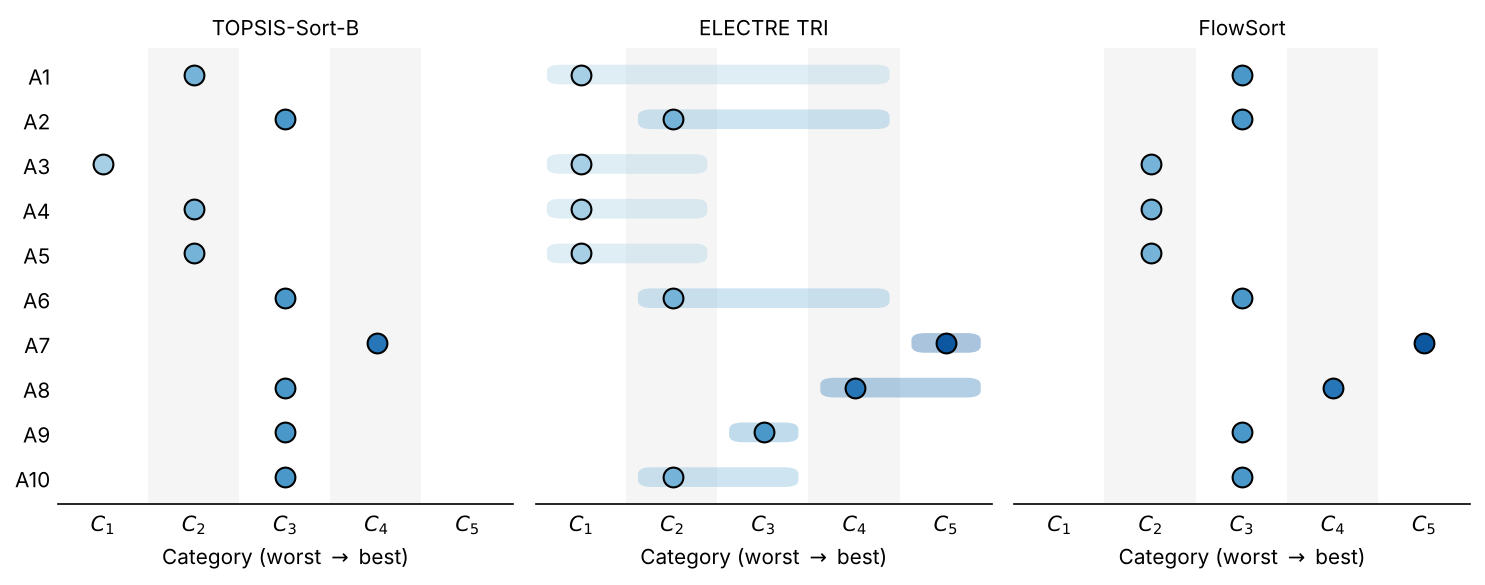

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4), dpi=150, sharey=True)

sorting_assignments(comparison['TOPSIS-Sort-B'], 5, labels=countries, ax=axes[0])
axes[0].set_title('TOPSIS-Sort-B', fontsize=10)

sorting_assignments(comparison['ELECTRE TRI (pessimistic)'], 5, labels=countries,
                    intervals=comparison[['ELECTRE TRI (pessimistic)', 'ELECTRE TRI (optimistic)']].to_numpy(),
                    ax=axes[1])
axes[1].set_title('ELECTRE TRI', fontsize=10)

sorting_assignments(comparison['FlowSort'], 5, labels=countries, ax=axes[2])
axes[2].set_title('FlowSort', fontsize=10)

plt.tight_layout()
plt.show()

TOPSIS-Sort and FlowSort aggregate all criteria into one value (closeness coefficient, net flow), so good values
on some criteria compensate bad values on others. ELECTRE TRI is not compensatory: in the pessimistic procedure an
alternative has to be at least as good as the lower profile on a sufficient majority of criteria. Countries with
uneven values, such as $A_1$, $A_2$ and $A_6$, therefore obtain wide intervals of categories in ELECTRE TRI, and
their pessimistic categories are worse than the categories given by the compensatory methods.

## References

- Mousseau, V., Słowiński, R., & Zielniewicz, P. (2000). A user-oriented implementation of the ELECTRE-TRI method
  integrating preference elicitation support. *Computers & Operations Research*, 27(7-8), 757-777.
- de Lima Silva, D. F., & de Almeida Filho, A. T. (2020). Sorting with TOPSIS through boundary and characteristic
  profiles. *Computers & Industrial Engineering*, 141, 106328.
- Nemery, P., & Lamboray, C. (2008). FlowSort: a flow-based sorting method with limiting or central profiles.
  *TOP*, 16(1), 90-113.